In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [24]:
df_resultados = pd.read_csv('csv/resultados_prueba_modelo.csv')
df_resultados.info()  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   nombre_imagen               120 non-null    object 
 1   ruta_imagen_original        120 non-null    object 
 2   calidad                     120 non-null    int64  
 3   formato_entrada             120 non-null    object 
 4   formato_salida              120 non-null    object 
 5   metodo                      120 non-null    object 
 6   lpips_estimado_original     120 non-null    float64
 7   lpips_estimado_no_negativo  120 non-null    float64
 8   prediccion_negativa         120 non-null    bool   
 9   lpips_real                  120 non-null    float64
 10  ruta_imagen_recodificada    120 non-null    object 
dtypes: bool(1), float64(3), int64(1), object(6)
memory usage: 9.6+ KB


ANÁLISIS DE PREDICCIONES NEGATIVAS
Total de imágenes evaluadas: 120
Predicciones negativas:      0 (0.00%)
Predicciones no negativas:   120 (100.00%)


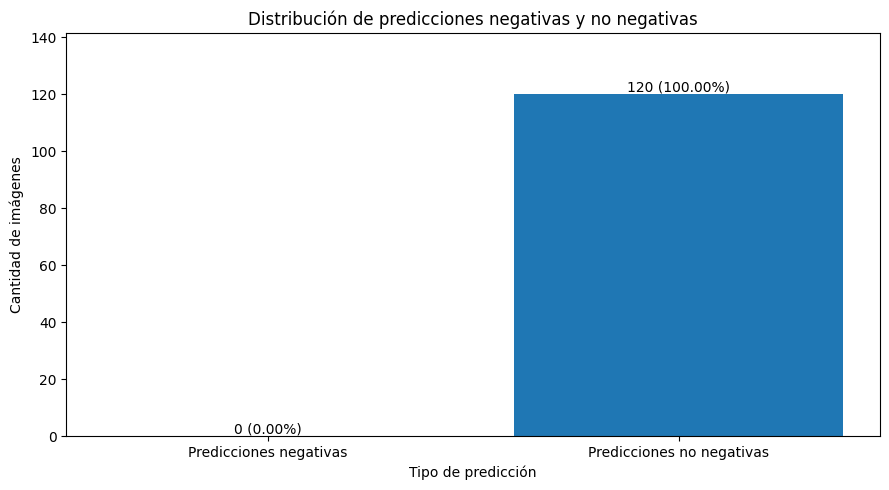

In [25]:
# ============================================================
# 1. CONTAR PREDICCIONES NEGATIVAS
# ============================================================

total = len(df_resultados)

negativas = int(df_resultados["prediccion_negativa"].sum())
no_negativas = total - negativas

porcentaje_negativas = negativas / total * 100 if total else 0
porcentaje_no_negativas = no_negativas / total * 100 if total else 0

print("=" * 55)
print("ANÁLISIS DE PREDICCIONES NEGATIVAS")
print("=" * 55)
print(f"Total de imágenes evaluadas: {total}")
print(f"Predicciones negativas:      {negativas} ({porcentaje_negativas:.2f}%)")
print(f"Predicciones no negativas:   {no_negativas} ({porcentaje_no_negativas:.2f}%)")

# ============================================================
# 2. GRÁFICA COMPARATIVA
# ============================================================

categorias = ["Predicciones negativas", "Predicciones no negativas"]
cantidades = [negativas, no_negativas]
porcentajes = [porcentaje_negativas, porcentaje_no_negativas]

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(categorias, cantidades)

ax.set_title("Distribución de predicciones negativas y no negativas")
ax.set_ylabel("Cantidad de imágenes")
ax.set_xlabel("Tipo de predicción")
ax.set_ylim(0, max(cantidades + [1]) * 1.18)

for barra, cantidad, porcentaje in zip(barras, cantidades, porcentajes):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{cantidad} ({porcentaje:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

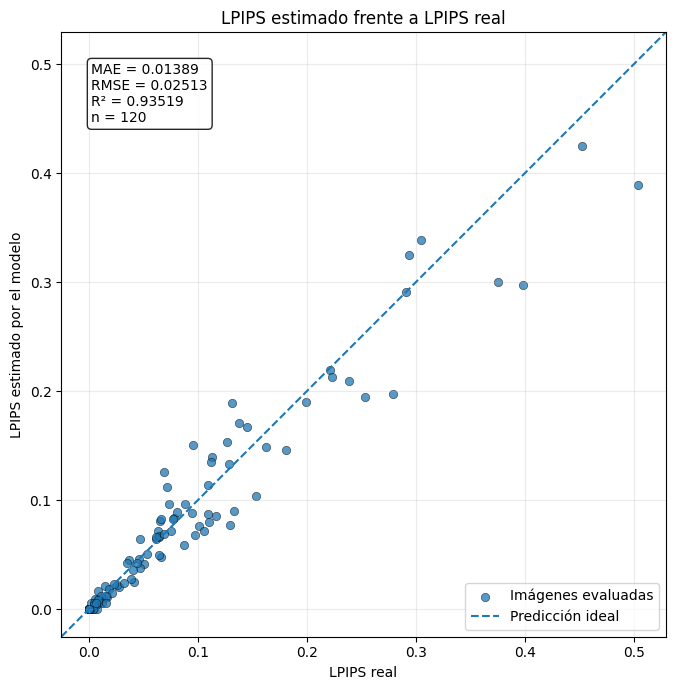

COMPARACIÓN DE LPIPS ESTIMADO VS. REAL
Imágenes comparadas: 120
MAE:  0.013886
RMSE: 0.025133
R²:   0.93519
Figura guardada en: D:\TrabajoGrado\Codigos\Funciones_Matematicas\resultados_optimizacion\comparacion_lpips_estimado_vs_real.png


In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================================
# 1. COMPARACIÓN: LPIPS ESTIMADO ORIGINAL VS. LPIPS REAL
# ============================================================

# Seleccionar las columnas necesarias y excluir valores nulos
df_comparacion = df_resultados[
    ["lpips_estimado_original", "lpips_real"]
].dropna().copy()

if df_comparacion.empty:
    raise ValueError("No hay datos válidos para realizar la comparación.")

y_estimado = df_comparacion["lpips_estimado_original"].to_numpy()
y_real = df_comparacion["lpips_real"].to_numpy()

# ============================================================
# 2. CALCULAR MÉTRICAS
# ============================================================

mae = mean_absolute_error(y_real, y_estimado)
rmse = np.sqrt(mean_squared_error(y_real, y_estimado))
r2 = r2_score(y_real, y_estimado)

# Límites comunes para ambos ejes
limite_min = min(y_real.min(), y_estimado.min())
limite_max = max(y_real.max(), y_estimado.max())

# Evitar límites idénticos si todos los valores fueran iguales
if limite_min == limite_max:
    margen = max(abs(limite_min) * 0.05, 0.001)
else:
    margen = (limite_max - limite_min) * 0.05

limite_inferior = limite_min - margen
limite_superior = limite_max + margen

# ============================================================
# 3. GENERAR GRÁFICA
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(
    y_real,
    y_estimado,
    alpha=0.75,
    edgecolors="black",
    linewidths=0.4,
    label="Imágenes evaluadas"
)

# Línea ideal: LPIPS estimado = LPIPS real
ax.plot(
    [limite_inferior, limite_superior],
    [limite_inferior, limite_superior],
    linestyle="--",
    linewidth=1.5,
    label="Predicción ideal"
)

ax.set_xlim(limite_inferior, limite_superior)
ax.set_ylim(limite_inferior, limite_superior)
ax.set_aspect("equal", adjustable="box")

ax.set_title("LPIPS estimado frente a LPIPS real")
ax.set_xlabel("LPIPS real")
ax.set_ylabel("LPIPS estimado por el modelo")

ax.text(
    0.05,
    0.95,
    f"MAE = {mae:.5f}\n"
    f"RMSE = {rmse:.5f}\n"
    f"R² = {r2:.5f}\n"
    f"n = {len(df_comparacion)}",
    transform=ax.transAxes,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.85
    )
)

ax.legend()
ax.grid(True, alpha=0.25)
plt.tight_layout()

# ============================================================
# 4. GUARDAR LA FIGURA
# ============================================================

CARPETA_RESULTADOS = Path("resultados_optimizacion")
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

ruta_figura = (
    CARPETA_RESULTADOS
    / "comparacion_lpips_estimado_vs_real.png"
)

plt.savefig(
    ruta_figura,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 5. MOSTRAR RESULTADOS
# ============================================================

print("=" * 55)
print("COMPARACIÓN DE LPIPS ESTIMADO VS. REAL")
print("=" * 55)
print(f"Imágenes comparadas: {len(df_comparacion)}")
print(f"MAE:  {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²:   {r2:.5f}")
print(f"Figura guardada en: {ruta_figura.resolve()}")

In [27]:
import pandas as pd
from pathlib import Path

# ============================================================
# TABLA COMPARATIVA: LPIPS PREDICHO VS. REAL PARA LAS 120 IMÁGENES
# ============================================================

tabla_lpips = df_resultados[
    [
        "nombre_imagen",
        "formato_entrada",
        "formato_salida",
        "metodo",
        "calidad",
        "lpips_estimado_original",
        "lpips_real"
    ]
].copy()

# Calcular el error absoluto por imagen
tabla_lpips["error_absoluto"] = (
    tabla_lpips["lpips_estimado_original"]
    - tabla_lpips["lpips_real"]
).abs()

# Renombrar las columnas para facilitar su interpretación
tabla_lpips = tabla_lpips.rename(columns={
    "nombre_imagen": "Imagen",
    "formato_entrada": "Formato original",
    "formato_salida": "Formato de salida",
    "metodo": "Método",
    "calidad": "Calidad",
    "lpips_estimado_original": "LPIPS predicho",
    "lpips_real": "LPIPS real",
    "error_absoluto": "Error absoluto"
})

# Mostrar seis decimales en los valores numéricos
columnas_numericas = [
    "LPIPS predicho",
    "LPIPS real",
    "Error absoluto"
]

tabla_lpips[columnas_numericas] = (
    tabla_lpips[columnas_numericas].round(6)
)

# Mostrar las 120 filas en el notebook
print(f"Total de imágenes: {len(tabla_lpips)}")
display(tabla_lpips)

# Guardar la tabla completa en CSV
ruta_tabla = (
    Path('carpeta_resultados')
    / "tabla_comparacion_lpips_120_imagenes.csv"
)

tabla_lpips.to_csv(
    ruta_tabla,
    index=False,
    encoding="utf-8-sig"
)

print("\nTabla guardada en:")
print(ruta_tabla.resolve())

Total de imágenes: 120


,Imagen,Formato original,Formato de salida,Método,Calidad,LPIPS predicho,LPIPS real,Error absoluto
0,COCO_test2014_000000000862.jpg,jpg,webp,imagemagick,10,0.339245,0.305163,0.034082
1,COCO_test2014_000000020048.jpg,jpg,webp,imagemagick,50,0.096311,0.088087,0.008224
2,COCO_test2014_000000020892.jpg,jpg,webp,pillow,30,0.081105,0.065788,0.015318
3,COCO_test2014_000000021917.jpg,jpg,webp,imagemagick,90,0.009281,0.008904,0.000377
4,COCO_test2014_000000060759.jpg,jpg,webp,imagemagick,70,0.088136,0.094389,0.006253
...,...,...,...,...,...,...,...,...
115,t10f_20260130003745_000053_1958704d.webp,webp,jpg,imagemagick,90,0.005926,0.006632,0.000706
116,t10f_20260130003745_000845_c8eb6b04.webp,webp,jpg,ffmpeg,50,0.085895,0.116456,0.030561
117,t10f_20260130003745_000982_d26a8080.webp,webp,jpg,imagemagick,50,0.042146,0.044559,0.002413
118,t10f_20260130005002_000247_de26d343.webp,webp,png,imagemagick,50,0.000000,0.000000,0.000000



Tabla guardada en:
D:\TrabajoGrado\Codigos\Funciones_Matematicas\carpeta_resultados\tabla_comparacion_lpips_120_imagenes.csv


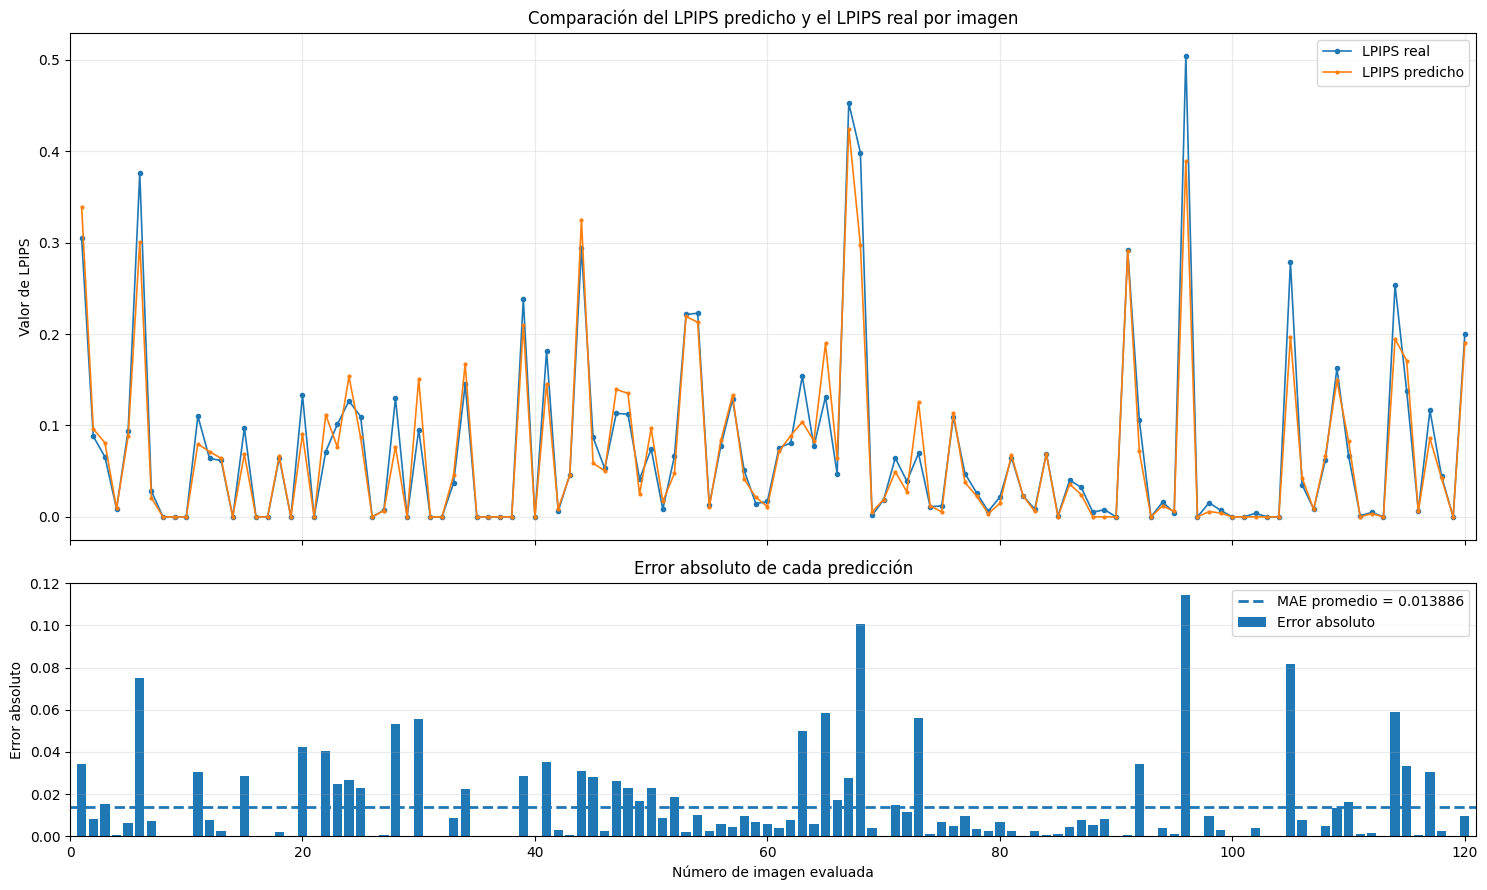

COMPARACIÓN DE PREDICCIONES Y ERRORES
Imágenes analizadas: 120
MAE promedio: 0.013886
Error absoluto máximo: 0.114570
Figura guardada en: D:\TrabajoGrado\Codigos\Funciones_Matematicas\carpeta_resultados\comparacion_prediccion_error_absoluto.png


In [28]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. CARGAR LA TABLA DE LAS 120 IMÁGENES
# ============================================================

ruta_csv = Path(
    r"D:\TrabajoGrado\Codigos\Funciones_Matematicas"
    r"\carpeta_resultados\tabla_comparacion_lpips_120_imagenes.csv"
)

df = pd.read_csv(ruta_csv)

# Comprobar los nombres de las columnas
col_pred = "LPIPS predicho"
col_real = "LPIPS real"

if col_pred not in df.columns or col_real not in df.columns:
    raise ValueError(
        f"No se encontraron las columnas esperadas. "
        f"Columnas disponibles: {list(df.columns)}"
    )

df[col_pred] = pd.to_numeric(df[col_pred], errors="coerce")
df[col_real] = pd.to_numeric(df[col_real], errors="coerce")
df = df.dropna(subset=[col_pred, col_real]).copy()

# Calcular el error absoluto individual
df["Error absoluto"] = (
    df[col_pred] - df[col_real]
).abs()

# Identificador de cada observación
df["N.º de imagen"] = np.arange(1, len(df) + 1)

# Error absoluto promedio
mae = df["Error absoluto"].mean()

# ============================================================
# 2. CREAR UNA FIGURA CON DOS GRÁFICOS
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(15, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

x = df["N.º de imagen"]

# ------------------------------------------------------------
# GRÁFICO SUPERIOR: LPIPS PREDICHO VS. LPIPS REAL
# ------------------------------------------------------------

ax1.plot(
    x,
    df[col_real],
    marker="o",
    markersize=3,
    linewidth=1.2,
    label="LPIPS real"
)

ax1.plot(
    x,
    df[col_pred],
    marker=".",
    markersize=4,
    linewidth=1.2,
    label="LPIPS predicho"
)

ax1.set_title(
    "Comparación del LPIPS predicho y el LPIPS real por imagen"
)
ax1.set_ylabel("Valor de LPIPS")
ax1.legend()
ax1.grid(True, alpha=0.25)

# ------------------------------------------------------------
# GRÁFICO INFERIOR: ERROR ABSOLUTO POR IMAGEN
# ------------------------------------------------------------

ax2.bar(
    x,
    df["Error absoluto"],
    width=0.8,
    label="Error absoluto"
)

ax2.axhline(
    mae,
    linestyle="--",
    linewidth=2,
    label=f"MAE promedio = {mae:.6f}"
)

ax2.set_title("Error absoluto de cada predicción")
ax2.set_xlabel("Número de imagen evaluada")
ax2.set_ylabel("Error absoluto")
ax2.legend()
ax2.grid(axis="y", alpha=0.25)

ax2.set_xlim(0, len(df) + 1)

plt.tight_layout()

# ============================================================
# 3. GUARDAR Y MOSTRAR
# ============================================================

carpeta_salida = ruta_csv.parent
ruta_figura = carpeta_salida / "comparacion_prediccion_error_absoluto.png"

plt.savefig(
    ruta_figura,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 60)
print("COMPARACIÓN DE PREDICCIONES Y ERRORES")
print("=" * 60)
print(f"Imágenes analizadas: {len(df)}")
print(f"MAE promedio: {mae:.6f}")
print(f"Error absoluto máximo: {df['Error absoluto'].max():.6f}")
print(f"Figura guardada en: {ruta_figura.resolve()}")

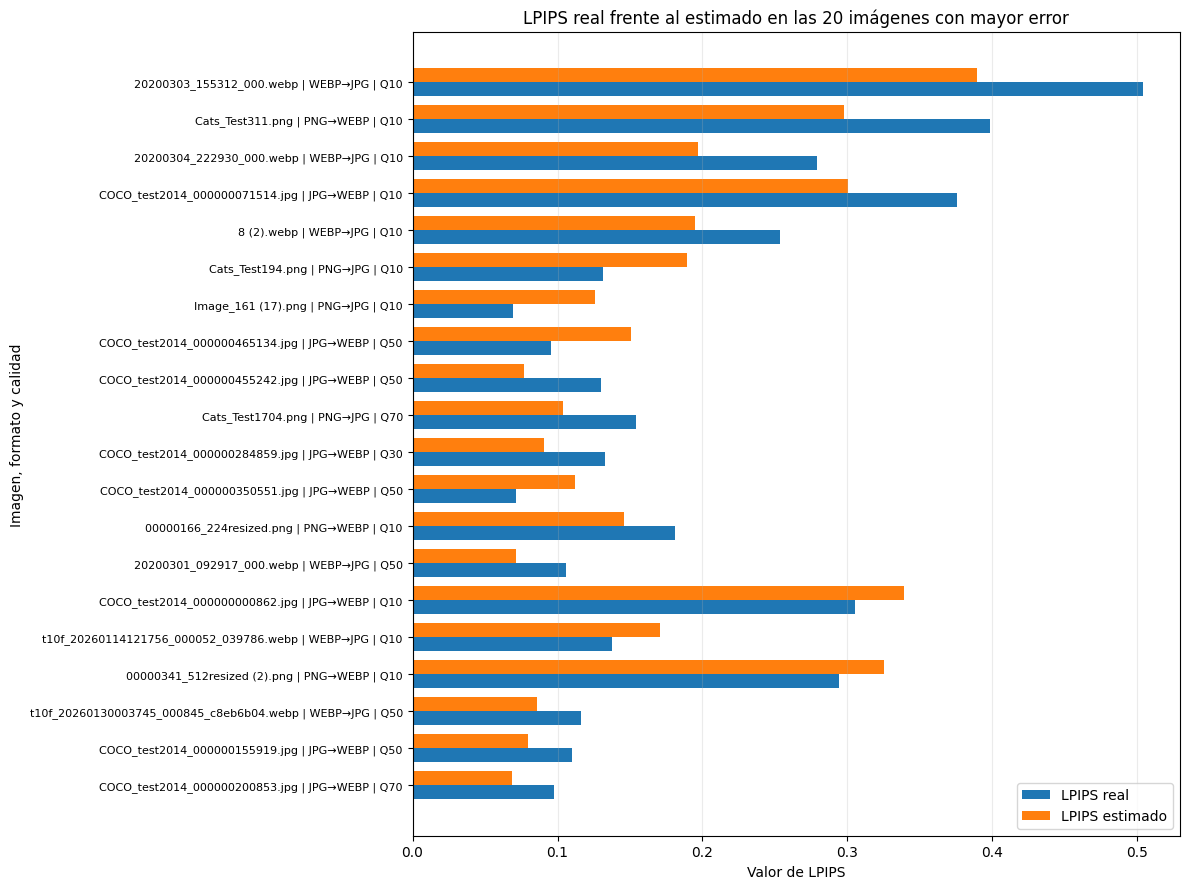

Figura guardada en: D:\TrabajoGrado\Codigos\Funciones_Matematicas\carpeta_resultados\comparacion_lpips_top20_errores.png

Imágenes con mayor error absoluto:


,nombre_imagen,formato_entrada,formato_salida,metodo,calidad,lpips_estimado_original,lpips_real,error_absoluto
0,20200303_155312_000.webp,webp,jpg,pillow,10,0.389604,0.504174,0.114570
1,Cats_Test311.png,png,webp,pillow,10,0.297565,0.398424,0.100858
2,20200304_222930_000.webp,webp,jpg,ffmpeg,10,0.197089,0.278876,0.081786
3,COCO_test2014_000000071514.jpg,jpg,webp,pillow,10,0.300659,0.375753,0.075093
4,8 (2).webp,webp,jpg,imagemagick,10,0.194527,0.253476,0.058949
5,Cats_Test194.png,png,jpg,ffmpeg,10,0.189663,0.131385,0.058278
6,Image_161 (17).png,png,jpg,pillow,10,0.125697,0.069491,0.056206
7,COCO_test2014_000000465134.jpg,jpg,webp,ffmpeg,50,0.150785,0.095385,0.055400
8,COCO_test2014_000000455242.jpg,jpg,webp,imagemagick,50,0.076965,0.130026,0.053061
9,Cats_Test1704.png,png,jpg,imagemagick,70,0.103953,0.153906,0.049953


In [29]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# COMPARACIÓN DEL LPIPS ESTIMADO Y REAL EN LOS CASOS CON MAYOR ERROR
# ============================================================

df_comp = df_resultados.copy()

df_comp["error_absoluto"] = (
    df_comp["lpips_estimado_original"] - df_comp["lpips_real"]
).abs()

# Seleccionar las 20 imágenes con mayor discrepancia
top_20 = (
    df_comp.nlargest(20, "error_absoluto")
    .sort_values("error_absoluto", ascending=True)
    .copy()
)

# Etiquetas para identificar cada caso
top_20["etiqueta"] = (
    top_20["nombre_imagen"].astype(str)
    + " | "
    + top_20["formato_entrada"].astype(str).str.upper()
    + "→"
    + top_20["formato_salida"].astype(str).str.upper()
    + " | Q"
    + top_20["calidad"].astype(str)
)

# ============================================================
# GRÁFICA DE BARRAS HORIZONTALES COMPARATIVAS
# ============================================================

y = np.arange(len(top_20))
altura = 0.38

fig, ax = plt.subplots(figsize=(12, 9))

ax.barh(
    y - altura / 2,
    top_20["lpips_real"],
    height=altura,
    label="LPIPS real"
)

ax.barh(
    y + altura / 2,
    top_20["lpips_estimado_original"],
    height=altura,
    label="LPIPS estimado"
)

ax.set_yticks(y)
ax.set_yticklabels(top_20["etiqueta"], fontsize=8)
ax.set_xlabel("Valor de LPIPS")
ax.set_ylabel("Imagen, formato y calidad")
ax.set_title("LPIPS real frente al estimado en las 20 imágenes con mayor error")
ax.legend()
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

ruta_figura = (
    Path('carpeta_resultados')
    / "comparacion_lpips_top20_errores.png"
)

plt.savefig(ruta_figura, dpi=300, bbox_inches="tight")
plt.show()

print("Figura guardada en:", ruta_figura.resolve())
print("\nImágenes con mayor error absoluto:")
display(
    top_20[
        [
            "nombre_imagen",
            "formato_entrada",
            "formato_salida",
            "metodo",
            "calidad",
            "lpips_estimado_original",
            "lpips_real",
            "error_absoluto"
        ]
    ].sort_values("error_absoluto", ascending=False).reset_index(drop=True)
)